In [1]:
import numpy as np
import diversfun as fun
import matplotlib.pyplot as plt

fun.Colorblind(True)
fun.useTex(True)

### Spatiotemporal wavefront shaping

In [2]:
N = 240                              # Number of pixels in the diffuser and in the speckle
nFigs = 101                          # Number of frames in the time domain
angle = 120                          # Angle of the black rotaing angle

RMax = 0.9                           # Radius of the pupil (Max = 1)
DMDs = fun.SectionMask(N, nFigs, angle, Max=RMax) # Generarting turning masks
Amps, Frqs = fun.HarmComb(DMDs, 5)   # Calculating the frequency comb
Harms = fun.Harmonics(DMDs, 2, 5)    # Calculating the harmonics

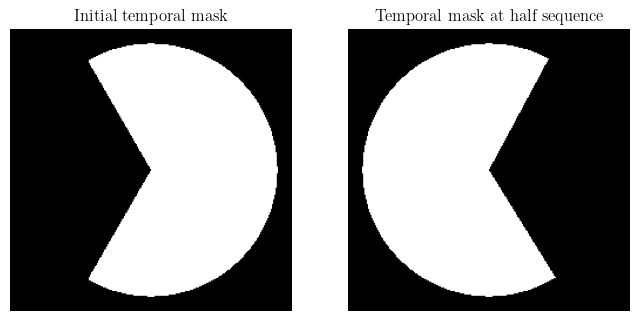

In [3]:
fig, ax = plt.subplots(1,2, figsize=(8, 4))
ax[0].imshow(np.abs(DMDs[0]), cmap='Greys_r')
ax[0].axis('off')
ax[0].set_title('Initial temporal mask')

ax[1].imshow(np.abs(DMDs[50]), cmap='Greys_r')
ax[1].axis('off')
ax[1].set_title('Temporal mask at half sequence')

plt.show()

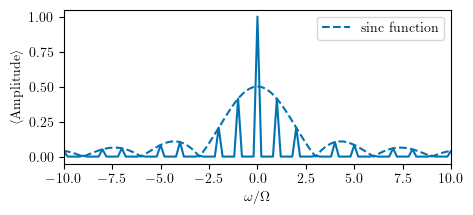

In [4]:
# Envelope
_frqs = np.linspace(-20, 20, 1001)
_Nangle = (2*np.pi)/(2*angle*np.pi/360)
_amps = np.abs(np.sinc(_frqs/_Nangle))/(_Nangle-1)

plt.figure(figsize=(5, 2))
plt.plot(Frqs, Amps, c='C0')
plt.plot(_frqs, _amps, ls='--', c='C0', label='sinc function')
plt.xlabel(r'$\omega/\Omega$')
plt.ylabel(r'$\langle$Amplitude$\rangle$')
plt.xlim(-10, 10)
plt.legend()
plt.show()

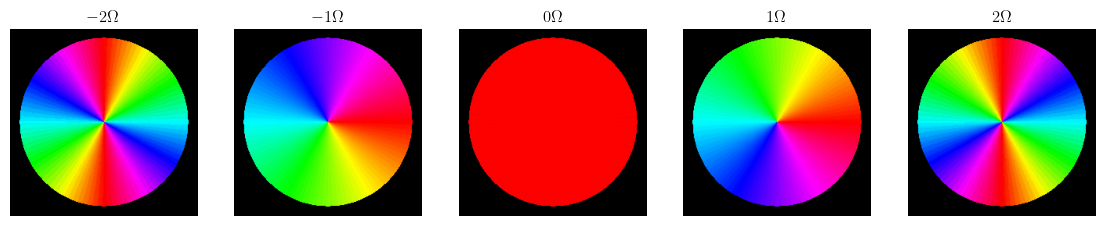

In [5]:
fig, ax = plt.subplots(1,5, figsize=(14, 4))
for i in range(len(Harms)):
    ax[i].imshow(fun.Colorize(Harms[i].T))
    ax[i].axis('off')
    ax[i].set_title(rf'${i-2}\Omega$')

plt.show()

## Phase plate

### Ground truth

In [6]:
N = 240                              # Number of pixels in the diffuser and in the speckle
NPad = 10                            # Padding of the image
Bin = 8                              # Binning of the diffuser pixels

RMax = 0.9                           # Radius of the pupil (Max = 1)
angle = 180                          # Angle of the black rotaing angle

Seed = 0
            # Creating phase mask                  Round pupil
Diffuser = fun.PhaseDiffuserBinning(N, Bin, Seed)*fun.VortexMask(N, 0, Max=RMax)
FF = fun.GetFarField(Diffuser, NPad) # Computing the Far Field
NF = fun.GetFarDiffuser(FF, NPad)    # Computing the Effective Near-field

# Generating the "measured" speckles of the sequence
Speckles = fun.GetExperimentDMD(Diffuser, angle, nFigs, 0, NPad=NPad, Max=RMax)
Harms = fun.Harmonics(Speckles, 1, 10, False) # Calculating the Harmonics of the intensity sequence

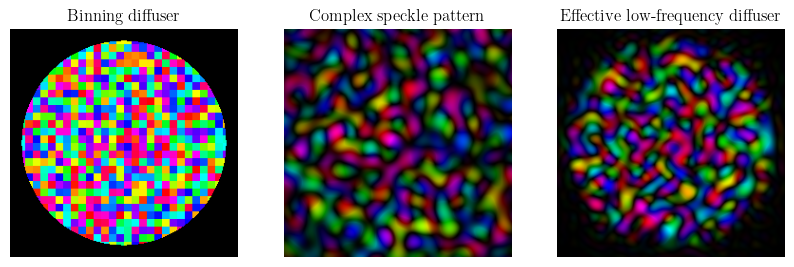

In [7]:
fig, ax = plt.subplots(1,3, figsize=(10, 4))
ax[0].imshow(fun.Colorize(Diffuser.T))
ax[0].axis('off')
ax[0].set_title('Binning diffuser')

ax[1].imshow(fun.Colorize(FF.T))
ax[1].axis('off')
ax[1].set_title('Complex speckle pattern')

ax[2].imshow(fun.Colorize(NF.T))
ax[2].axis('off')
ax[2].set_title('Effective low-frequency diffuser')

plt.show()

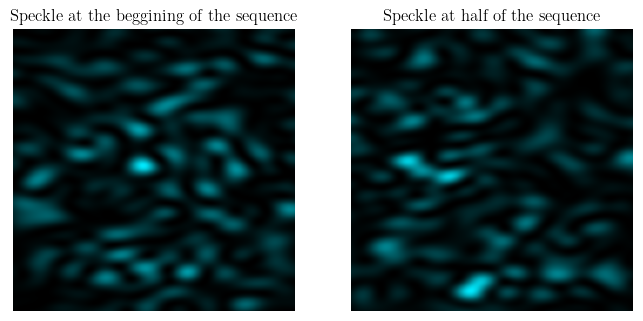

In [8]:
fig, ax = plt.subplots(1,2, figsize=(8, 4))
ax[0].imshow(Speckles[0], cmap=fun.ColorMaps('488nm'))
ax[0].axis('off')
ax[0].set_title('Speckle at the beggining of the sequence')

ax[1].imshow(Speckles[50], cmap=fun.ColorMaps('488nm'))
ax[1].axis('off')
ax[1].set_title('Speckle at half of the sequence')

plt.show()

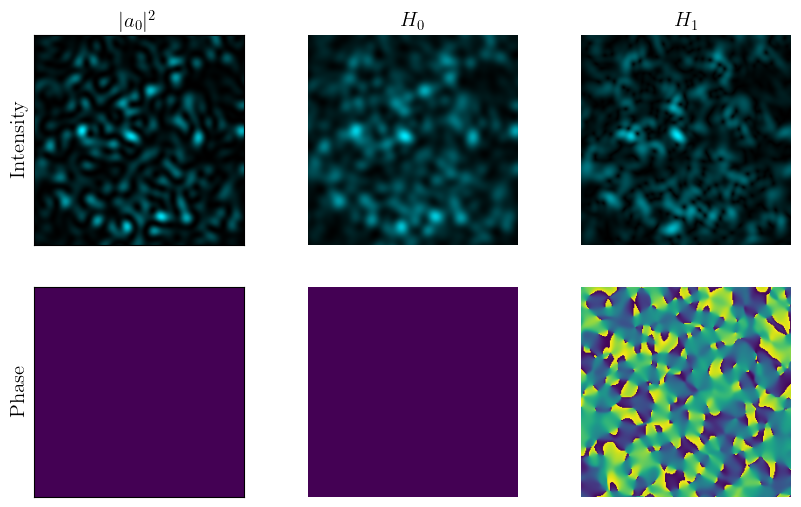

In [9]:
fig, ax = plt.subplots(2, 3, figsize=(10, 6))

ax[0,0].set_title(r'$|a_0|^2$', fontsize=15)
ax[0,0].set_ylabel('Intensity', fontsize=15)
ax[0,0].imshow(np.abs(FF)**2, cmap=fun.ColorMaps('488nm'))
ax[1,0].set_ylabel('Phase', fontsize=15)
ax[1,0].imshow(np.angle(np.abs(FF)**2))
for i in range(2):
    ax[i,0].set_xticks([])
    ax[i,0].set_yticks([])

ax[0,1].set_title(r'$H_0$', fontsize=15)
ax[0,1].imshow(np.abs(Harms[0]), cmap=fun.ColorMaps('488nm'))
ax[0,1].axis('off')
ax[1,1].imshow(np.angle(Harms[0]))
ax[1,1].axis('off')

ax[0,2].set_title(r'$H_1$', fontsize=15)
ax[0,2].imshow(np.abs(Harms[1]), cmap=fun.ColorMaps('488nm'))
ax[0,2].axis('off')
ax[1,2].imshow(np.angle(Harms[1]))
ax[1,2].axis('off')

plt.show()

### Reconstruction

In [10]:
Bin = 8                                 # Binning of the diffuser mask

# Loading the phase plate predicted by the algorithm
_FileName = f'Data/Num_Bin={Bin:02d}_N={N}_Seed={Seed:02d}.npy'
_theDict = np.load(_FileName, allow_pickle=True).item()

Diffuserp = _theDict['Diffuser']        # Phase plate
Loss = _theDict['TotLosses']            # Loss E
Time = _theDict['ElapsedTime']          # Elapsing time
Energy = _theDict['EnergyLoss']         # Maxima of the cross correlation spectrum

Diffuserp = Diffuserp*fun.VortexMask(N, 0, Max=RMax) 
FFp = fun.GetFarField(Diffuserp, NPad)  # Computing the  predicted Far Field
NFp = fun.GetFarDiffuser(FFp, NPad)     # Computing the effective Near-field

# Computing the three observables
VMasks = fun.VortexMask(N, 1, Max=RMax) # Helical masks
cp1, cm1 = fun.GetFourierConstants(angle*2*np.pi/360)  # Fourier coeffitiens

Specklesp = []
for _mask in VMasks:              # Far field corresponding to every helical mask
    _out = fun.Norm(fun.GetFarField(_mask*Diffuserp, NPad))
    Specklesp.append(_out.astype(complex))

# Computing the predicted H_0 and H_1 from the spiral phase diversity
H0p = np.abs(cm1*Specklesp[0])**2 + np.abs(Specklesp[1])**2 + np.abs(cp1*Specklesp[2])**2
H1p = cm1*Specklesp[1]*Specklesp[0].conj() + cp1*Specklesp[2]*Specklesp[1].conj()

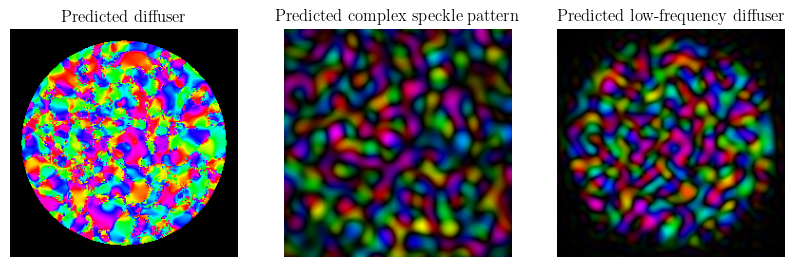

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(10, 4))
ax[0].imshow(fun.Colorize(Diffuserp.T))
ax[0].axis('off')
ax[0].set_title('Predicted diffuser')

ax[1].imshow(fun.Colorize(FFp.T))
ax[1].axis('off')
ax[1].set_title('Predicted complex speckle pattern')

ax[2].imshow(fun.Colorize(NFp.T))
ax[2].axis('off')
ax[2].set_title('Predicted low-frequency diffuser')

plt.show()

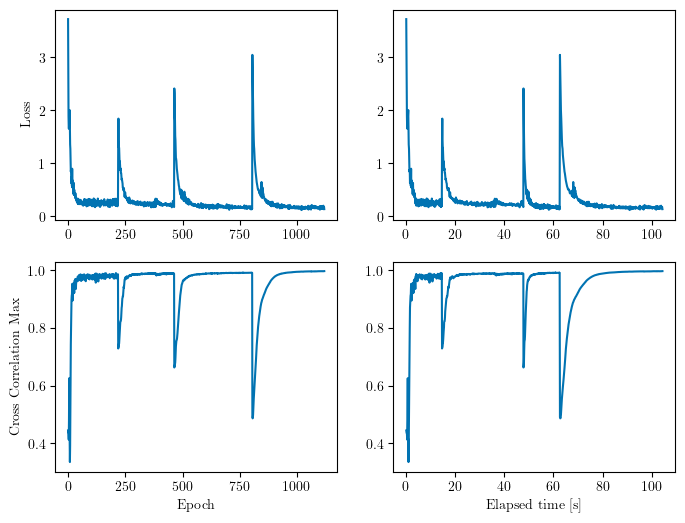

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(8, 6))
ax[0,0].plot(Loss)
ax[0,0].set_ylabel('Loss')

ax[0,1].plot(Time, Loss)

ax[1,0].plot(Energy)
ax[1,0].set_ylabel('Cross Correlation Max')
ax[1,0].set_xlabel('Epoch')

ax[1,1].plot(Time, Energy)
ax[1,1].set_xlabel('Elapsed time [s]')
plt.show()

# Each peak shows the change of the pixel size

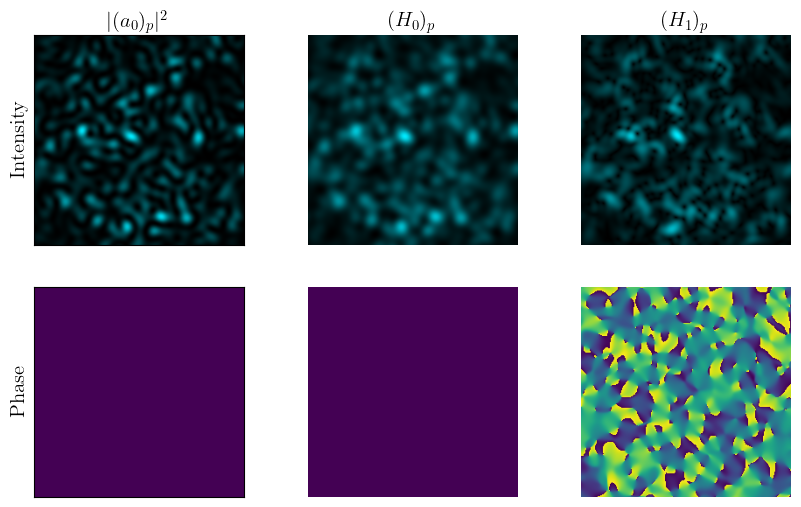

In [13]:
fig, ax = plt.subplots(2, 3, figsize=(10, 6))

ax[0,0].set_title(r'$|(a_0)_p|^2$', fontsize=15)
ax[0,0].set_ylabel('Intensity', fontsize=15)
ax[0,0].imshow(np.abs(FFp)**2, cmap=fun.ColorMaps('488nm'))
ax[1,0].set_ylabel('Phase', fontsize=15)
ax[1,0].imshow(np.angle(np.abs(FF)**2))
for i in range(2):
    ax[i,0].set_xticks([])
    ax[i,0].set_yticks([])

ax[0,1].set_title(r'$(H_0)_p$', fontsize=15)
ax[0,1].imshow(np.abs(H0p), cmap=fun.ColorMaps('488nm'))
ax[0,1].axis('off')
ax[1,1].imshow(np.angle(H0p))
ax[1,1].axis('off')

ax[0,2].set_title(r'$(H_1)_p$', fontsize=15)
ax[0,2].imshow(np.abs(H1p), cmap=fun.ColorMaps('488nm'))
ax[0,2].axis('off')
ax[1,2].imshow(np.angle(H1p))
ax[1,2].axis('off')

plt.show()

### Comparison

In [14]:
print(rf'Correlation coefficient a_0^2: {np.corrcoef((np.abs(FF)**2).ravel(), (np.abs(FFp)**2).ravel())[0,1]}')
print(rf'Correlation coefficient H_0: {np.corrcoef(Harms[0].ravel(), H0p.ravel())[0,1]}')
print(rf'Correlation coefficient H_1: {np.corrcoef(Harms[1].ravel(), H1p.ravel())[0,1]}')

Correlation coefficient a_0^2: 0.9989377740828825
Correlation coefficient H_0: (0.9970529897246331+0j)
Correlation coefficient H_1: (0.999236652579022+0.0002574212351686257j)


In [15]:
DiffD = (np.angle(NF)-np.angle(NFp))%(2*np.pi)-np.pi            # Difference of the near field
DiffP = (np.angle(FF)-np.angle(FFp))%(2*np.pi)-np.pi            # Difference of the far field

I = np.abs(FF)**2/np.max(np.abs(FF)**2)
Ip = np.abs(FFp)**2/np.max(np.abs(FFp)**2)
DiffI = I-Ip                                                    # Difference of the intensity (residual map)

# Computing the cross-correlation spectrum 
CC = np.abs(np.fft.fftshift(np.fft.fft2(FF*FFp.conj())))
CC = CC/np.sqrt(np.sum(np.abs(FF)**2) * np.sum(np.abs(FFp)**2))
CC = fun.CropCenter(CC, 50)

# Removing intensity fluctuations
CCf = np.abs(np.fft.fftshift(np.fft.fft2(np.exp(1j*(np.angle(FF)-np.angle(FFp))))))
CCf = CCf/N**2
CCf = fun.CropCenter(CCf, 50)

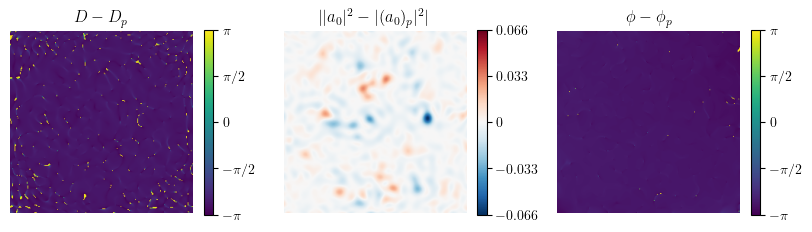

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(10, 4))
_im = ax[0].imshow(DiffD, vmin=-np.pi, vmax=np.pi)
ax[0].axis('off')
ax[0].set_title('$D-D_p$')
cbar = plt.colorbar(_im, shrink=0.6, ticks=[-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
cbar.ax.set_yticklabels([r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$'])

_im = ax[1].imshow(DiffI, cmap='RdBu_r', vmin=-np.max(np.abs(DiffI)), vmax=np.max(np.abs(DiffI)))
ax[1].axis('off')
ax[1].set_title(r'$\left||a_0|^2-|(a_0)_p|^2\right|$')
cbar = plt.colorbar(_im, shrink=0.6, 
                    ticks=[-np.max(np.abs(DiffI)), -np.max(np.abs(DiffI))/2, 0, np.max(np.abs(DiffI))/2, np.max(np.abs(DiffI))])
cbar.ax.set_yticklabels([rf'${-np.max(np.abs(DiffI)):0.3f}$', rf'${-0.5*np.max(np.abs(DiffI)):0.3f}$', '$0$', 
                         rf'${0.5*np.max(np.abs(DiffI)):0.3f}$', rf'${np.max(np.abs(DiffI)):0.3f}$'])

_im = ax[2].imshow(DiffP, vmin=-np.pi, vmax=np.pi)
ax[2].axis('off')
ax[2].set_title(r'$\phi-\phi_p$')
cbar = plt.colorbar(_im, shrink=0.6, ticks=[-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
cbar.ax.set_yticklabels([r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$'])

plt.show()

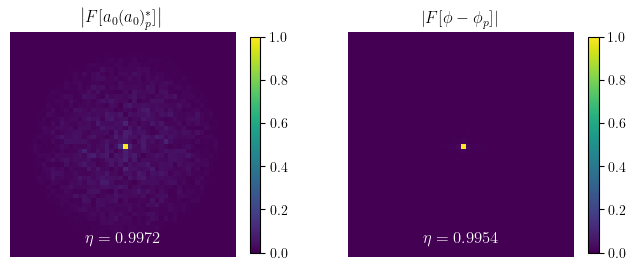

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
_im = ax[0].imshow(CC, vmin=0, vmax=1)
ax[0].axis('off')
ax[0].set_title(rf'$\left|F[a_0(a_0)_p^*]\right|$')
ax[0].text(0.5, 0.05, rf'$\eta={np.max(CC)**2:0.4f}$', color='white', weight='bold', fontsize=12, horizontalalignment='center',
               verticalalignment='bottom', transform=ax[0].transAxes)
cbar = plt.colorbar(_im, shrink=0.7)

_im = ax[1].imshow(CCf, vmin=0, vmax=1)
ax[1].axis('off')
ax[1].set_title(rf'$\left|F[\phi-\phi_p]\right|$')
ax[1].text(0.5, 0.05, rf'$\eta={np.max(CCf)**2:0.4f}$', color='white', weight='bold', fontsize=12, horizontalalignment='center',
               verticalalignment='bottom', transform=ax[1].transAxes)
cbar = plt.colorbar(_im, shrink=0.7)

plt.show()

### Vortex

In [18]:
VP, VM = fun.FindVortex(np.angle(FF))               # Finding positive and negative vortex of the Far field
VP_p, VM_p = fun.FindVortex(np.angle(FFp))          # Finding positive and negative vortex of the predicted Far field

# Computing positive and negative vortex and comparing distances for 10 realizations
_disPP = []
_disPM = []
_disMP = []
_disMM = []
for Seed in range(10):
    _FileName = f'Data/Num_Bin={Bin:02d}_N={N}_Seed={Seed:02d}.npy' # Loading diffuser computed by our algorithm
    _theDict = np.load(_FileName, allow_pickle=True).item()

    Diffuser = fun.PhaseDiffuserBinning(N, Bin, Seed)*fun.VortexMask(N, 0, Max=RMax)      # Original diffuser
    Diffuserp = _theDict['Diffuser']*fun.VortexMask(N, 0, Max=RMax)                       # Predicted diffuser

    FF = fun.GetFarField(Diffuser, NPad)                     # Original far field
    FFp = fun.GetFarField(Diffuserp, NPad)                   # Predicted far field
    gs = fun.GetGrainSize(np.abs(FF)**2)                     # Computing the grain size of the speckle

    vp, vm = fun.FindVortex(np.angle(FF))                    # Finding vortex of the original far field
    vpp, vmp = fun.FindVortex(np.angle(FFp))                 # Finding vortex of the predicted far field

    _disPP = np.append(_disPP, fun.FindDistances(vp, vpp, gs))      # Finding distances between vortex+ and vortex+ predicted
    _disPM = np.append(_disPM, fun.FindDistances(vp, vmp, gs))      # Finding distances between vortex+ and vortex- predicted
    _disMP = np.append(_disMP, fun.FindDistances(vm, vpp, gs))      # Finding distances between vortex- and vortex+ predicted
    _disMM = np.append(_disMM, fun.FindDistances(vm, vmp, gs))      # Finding distances between vortex- and vortex- predicted

# Computing the radial distribution of every set
_bins = np.linspace(0, 1.5, 30)
HistPP, EdgePP = fun.RadialHistogram(_disPP, _bins)
HistMM, EdgeMM = fun.RadialHistogram(_disMM, _bins)
HistPM, EdgePM = fun.RadialHistogram(_disPM, _bins)
HistMP, EdgeMP = fun.RadialHistogram(_disMP, _bins)

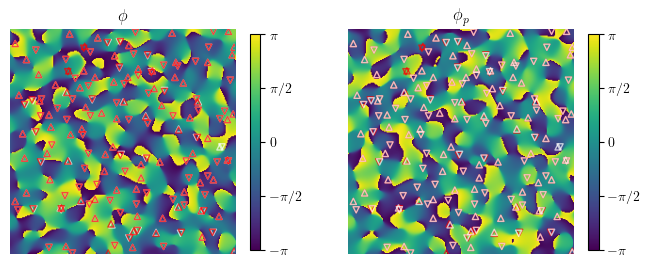

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
_im = ax[0].imshow(np.angle(FF), vmin=-np.pi, vmax=np.pi)
for _v in VP:
    ax[0].scatter(_v[0], _v[1], marker='^', ec='white', fc='none', s=20, alpha=0.7)
for _v in VM:
    ax[0].scatter(_v[0], _v[1], marker='v', ec='white', fc='none', s=20, alpha=0.7)
for _v in VP_p:
    ax[0].scatter(_v[0], _v[1], marker='^', ec='red', fc='none', s=20, alpha=0.7)
for _v in VM_p:
    ax[0].scatter(_v[0], _v[1], marker='v', ec='red', fc='none', s=20, alpha=0.7)
ax[0].axis('off')
ax[0].set_title(r'$\phi$')
cbar = plt.colorbar(_im, shrink=0.7, ticks=[-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
cbar.ax.set_yticklabels([r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$'])

_im = ax[1].imshow(np.angle(FFp), vmin=-np.pi, vmax=np.pi)
for _v in VP_p:
    ax[1].scatter(_v[0], _v[1], marker='^', ec='red', fc='none', s=20, alpha=0.7)
for _v in VM_p:
    ax[1].scatter(_v[0], _v[1], marker='v', ec='red', fc='none', s=20, alpha=0.7)
for _v in VP:
    ax[1].scatter(_v[0], _v[1], marker='^', ec='white', fc='none', s=20, alpha=0.7)
for _v in VM:
    ax[1].scatter(_v[0], _v[1], marker='v', ec='white', fc='none', s=20, alpha=0.7)
ax[1].axis('off')
ax[1].set_title(r'$\phi_p$')
cbar = plt.colorbar(_im, shrink=0.7, ticks=[-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
cbar.ax.set_yticklabels([r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$'])

plt.show()

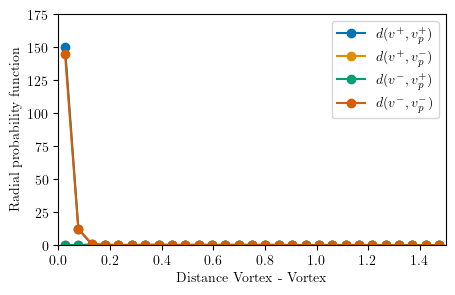

In [20]:
plt.figure(figsize=(5, 3))
plt.plot(EdgePP, HistPP, label=r'$d(v^+, v^+_p)$', marker='o')
plt.plot(EdgePM, HistPM, label=r'$d(v^+, v^-_p)$', marker='o')
plt.plot(EdgeMP, HistMP, label=r'$d(v^-, v^+_p)$', marker='o')
plt.plot(EdgeMM, HistMM, label=r'$d(v^-, v^-_p)$', marker='o')
plt.xlabel('Distance Vortex - Vortex')
plt.ylabel('Radial probability function')
plt.xlim(0, 1.5)
plt.ylim(0, 175)
plt.legend()
plt.xticks()
plt.yticks()
plt.show()